In [128]:
import pybamm
import matplotlib.pyplot as plt
import numpy as np

In [129]:
parameter_values = pybamm.ParameterValues("Chen2020") #Importing parameter values from the parameter set
parameter_values.set_initial_state(0) # Set initial state of charge to 0%
initial_soc = 0
Q_nom = parameter_values["Nominal cell capacity [A.h]"]
V_nom = 3.6
P_rates = [1, 2, 3, 4, 5]          # sadece P katsayıları
sols = {}
print(P_rates)

[1, 2, 3, 4, 5]


In [130]:
for P in P_rates:
    P_W = P * Q_nom * V_nom     # 1P = 18 W, 2P = 36 W...
    CPCV_Charging = pybamm.Experiment([
        f"Charge at {P_W} W until 4.2 V",
        "Hold at 4.2 V until C/20",
    ])
    sim = pybamm.Simulation(pybamm.lithium_ion.DFN(), experiment=CPCV_Charging,
                            parameter_values=parameter_values, solver=pybamm.IDAKLUSolver(rtol=1e-6, atol=1e-8))
    sols[P] = sim.solve()

CP Phase Time for 1P: 74.03% at time 47.32 min
CV Phase Time for 1P: 27.42% at time 55.67 min
Final SoC for 1P: 101.46% at time 102.99 min
SoC at 10 min for 1P: 17.21% at time 10 min
Time to reach 80% SoC for 5P: 52.34 min
****************************
CP Phase Time for 2P: 53.33% at time 17.39 min
CV Phase Time for 2P: 48.07% at time 68.25 min
Final SoC for 2P: 101.40% at time 85.63 min
SoC at 10 min for 2P: 31.73% at time 10 min
Time to reach 80% SoC for 5P: 33.46 min
****************************
CP Phase Time for 3P: 33.90% at time 7.46 min
CV Phase Time for 3P: 67.46% at time 75.72 min
Final SoC for 3P: 101.36% at time 83.18 min
SoC at 10 min for 3P: 43.41% at time 10 min
Time to reach 80% SoC for 5P: 30.19 min
****************************
CP Phase Time for 4P: 20.14% at time 3.34 min
CV Phase Time for 4P: 81.20% at time 79.53 min
Final SoC for 4P: 101.35% at time 82.87 min
SoC at 10 min for 4P: 46.49% at time 10 min
Time to reach 80% SoC for 5P: 29.56 min
**************************

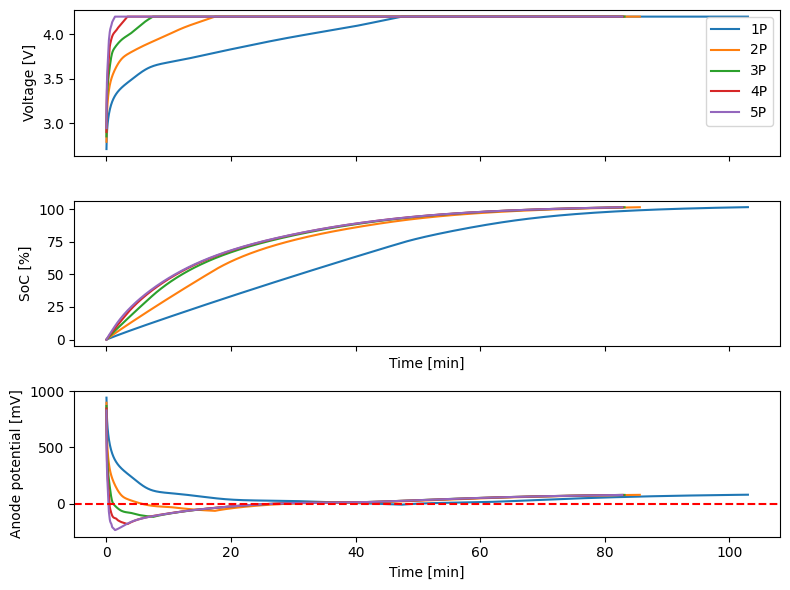

In [131]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(8, 6))
for P_rates, sol in sols.items():
    t   = sol["Time [min]"].entries
    soc = (initial_soc - sol["Discharge capacity [A.h]"].entries / Q_nom) * 100
    ax1.plot(t, sol["Voltage [V]"].entries, label=f"{P_rates}P")
    ax2.plot(t, soc, label=f"{P_rates}P")
    u = sol["Negative electrode surface potential difference at separator interface [V]"].entries * 1000  # V -> mV
    ax3.plot(t, u, label=f"{P_rates}P")
    t_first_end = sol.cycles[0]["Time [min]"].entries[-1] # time in the end of the first 
    t_second_end = sol.cycles[1]["Time [min]"].entries[-1] # time in the end of the second 
    t_end = sol.cycles[1]["Time [min]"].entries[-1]
    soc_end = np.interp(t_end, t, soc) # SoC Final 
    soc_10min = np.interp(10, t, soc) # SoC when time 10min
    soc_CP_end = np.interp(t_first_end, t, soc) #SoC in the end of the first step 
    soc_CV_end = np.interp(t_second_end, t, soc) # SoC in the end of the second step
    CV_Phase_Time = t_second_end - t_first_end # time just second step
    t_soc80 = np.interp(80, soc, t) # Time when SoC reaches 80%
    print(f"CP Phase Time for {P_rates}P: {soc_CP_end:.2f}% at time {t_first_end:.2f} min")
    print(f"CV Phase Time for {P_rates}P: {soc_CV_end - soc_CP_end:.2f}% at time {t_second_end - t_first_end:.2f} min")
    print(f"Final SoC for {P_rates}P: {soc_end:.2f}% at time {t_end:.2f} min")
    print(f"SoC at 10 min for {P_rates}P: {soc_10min:.2f}% at time 10 min")
    print(f"Time to reach 80% SoC for {P}P: {t_soc80:.2f} min")
    print("****************************")


ax1.set_ylabel("Voltage [V]");  ax1.legend()
ax2.set_ylabel("SoC [%]"); ax2.set_xlabel("Time [min]")
ax3.set_ylabel("Anode potential [mV]"); ax3.set_xlabel("Time [min]")
plt.axhline(0, color="red", linestyle="--")
plt.tight_layout(); plt.show()